In [14]:
import pandas as pd
import numpy as np

np.random.seed(23)

mu_vec1 = np.array([0,0,0])
cov_mat1 = np.array([[1,0,0],[0,1,0],[0,0,1]])
class1_sample = np.random.multivariate_normal(mu_vec1, cov_mat1, 20)
df = pd.DataFrame(class1_sample, columns=['feature1','feature2','feature3'])
df['target'] = 1

mu_vec2 = np.array([1,1,1])
cov_mat2 = np.array([[1,0,0],[0,1,0],[0,0,1]])
class1_sample = np.random.multivariate_normal(mu_vec2, cov_mat2, 20)
df1 = pd.DataFrame(class1_sample, columns=['feature1','feature2','feature3'])
df1['target'] = 0

df = pd.concat([df,df1], ignore_index=True)

df.sample(5)


,feature1,feature2,feature3,target
2,-0.367548,-1.137460,-1.322148,1
34,0.177061,-0.598109,1.226512,0
14,0.420623,0.411620,-0.071324,1
11,1.968435,-0.547788,-0.679418,1
12,-2.506230,0.146960,0.606195,1


In [15]:
import plotly.express as px
fig = px.scatter_3d(df, x='feature1', y='feature2', z='feature3', color='target')
fig.update_traces(marker=dict(size=5))
fig.update_layout(scene=dict(
                    xaxis_title='feature1',
                    yaxis_title='feature2',
                    zaxis_title='feature3'))
fig.show()

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df.iloc[:,:3] = scaler.fit_transform(df.iloc[:,:3])

In [17]:
covariance_matrix = np.cov([df.iloc[:,0],df.iloc[:,1],df.iloc[:,2]])
covariance_matrix

array([[1.02564103, 0.20478114, 0.080118  ],
       [0.20478114, 1.02564103, 0.19838882],
       [0.080118  , 0.19838882, 1.02564103]])

In [18]:
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/IPython/core/magics/pylab.py:166: UserWarning:

pylab import has clobbered these variables: ['mean', 'arrow']
`%matplotlib` prevents importing * from pylab and numpy



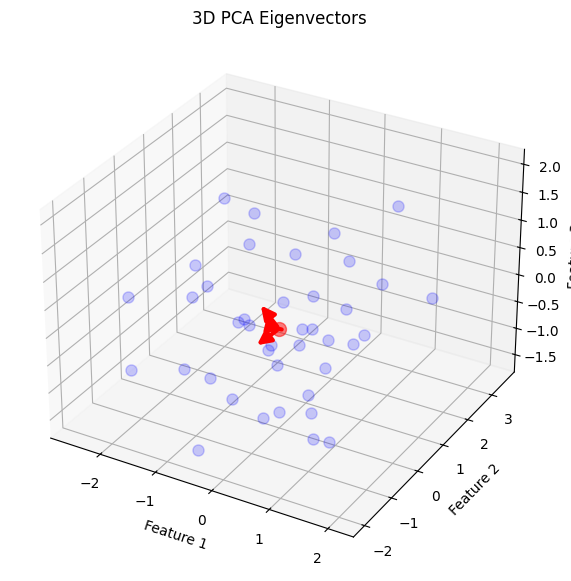

In [24]:
%pylab inline

from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d import proj3d
from matplotlib.patches import FancyArrowPatch

# Fixed Arrow3D class
class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def draw(self, renderer):
        xs3d, ys3d, zs3d = self._verts3d
        proj = self.axes.get_proj()  # Proper way to get projection matrix
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, proj)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        super().draw(renderer)

    def do_3d_projection(self, renderer=None):
        xs3d, ys3d, zs3d = self._verts3d
        proj = self.axes.get_proj()
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, proj)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        return np.min(zs)

# Plot
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection='3d')

# Scatter data points
ax.plot(df['feature1'], df['feature2'], df['feature3'], 'o', markersize=8, color='blue', alpha=0.2)

# Mean point
mean = [df['feature1'].mean(), df['feature2'].mean(), df['feature3'].mean()]
ax.plot([mean[0]], [mean[1]], [mean[2]], 'o', markersize=10, color='red', alpha=0.5)

# Plot eigenvectors
for v in eigen_vectors.T:
    v_scaled = v * 0.5
    arrow = Arrow3D([mean[0], mean[0] + v_scaled[0]],
                    [mean[1], mean[1] + v_scaled[1]],
                    [mean[2], mean[2] + v_scaled[2]],
                    mutation_scale=20, lw=3, arrowstyle="-|>", color="r")
    ax.add_artist(arrow)

ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')
plt.title('3D PCA Eigenvectors')

plt.show()

In [25]:
pc = eigen_vectors[0:2]
pc

array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442]])

In [28]:
transformed_df = np.dot(df.iloc[:,:3], pc.T)
new_df = pd.DataFrame(transformed_df,columns=['PC1','PC2'])
new_df['target'] = df['target'].values
new_df.sample(5)

,PC1,PC2,target
5,0.886733,0.522664,1
2,0.599433,1.795862,1
9,-0.997408,0.778938,1
19,1.304549,0.476645,1
25,-0.069178,-0.130994,0


In [29]:
new_df['target'] = new_df['target'].astype('str')
fig = px.scatter(x=new_df['PC1'],
                 y=new_df['PC2'],
                 color=new_df['target'],
                 color_discrete_sequence=px.colors.qualitative.G10
                )

fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))
fig.show()